# EMQA_L1_cy_extremes

**Case study: extremes of the current year, Romanian price and Brent**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_cy_extremes/EMQA_L1_cy_extremes.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Romanian daily base day-ahead price and Brent front-month close from 1 January of the current year to the cut-off, with the highest and lowest days marked; prints the daily and 15-minute extremes with their dates.

**Data:** 2026-01-01 to 2026-10-31, daily. **Source:** energy-charts.info (OPCOM prices); Yahoo Finance (BZ=F).

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
ZONE_SHORT = {'RO': 'RO (OPCOM PZU)', 'BG': 'BG (IBEX)', 'HU': 'HU (HUPX)', 'DE_LU': 'DE-LU (EPEX SPOT)'}


def month_ticks(ax, step=1):
    """Month axis 1..12: every month named, written vertically so it fits."""
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([MON_EN[m - 1] if (m - 1) % step == 0 else '' for m in range(1, 13)], fontsize=9, rotation=90)


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Data
Real series from the course repository (see `data/SOURCES.md`), cut at the last complete month; missing values stay missing.

In [3]:
# data cut-off: last complete calendar month common to the Romanian prices and the generation data
_p = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')['RO']
_g = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', usecols=['date_cet', 'hydro_run_of_river'],
                 parse_dates=['date_cet']).set_index('date_cet')['hydro_run_of_river']
_last = min(_p.dropna().index.max(), _g.dropna().index.max())
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
END_UTC = (END + pd.Timedelta(days=1)).tz_localize('Europe/Brussels').tz_convert('UTC')   # end of the CET day, in UTC
Y = END.year
print('data cut-off:', END.date())

# daily base prices (mean of all market time units of the CET/CEST day), EUR/MWh
P = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet').loc[:END]
# native-resolution day-ahead prices (60-min until Sep 2025, 15-min from 1 Oct 2025), CET/CEST clock
X = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
X.index = X.index.tz_convert('Europe/Brussels')
X = X.loc[:str(END.date())]
# Brent front-month futures (Yahoo Finance BZ=F), daily close in USD/bbl
F = pd.read_csv(DATA + 'fuels_daily.csv', parse_dates=['date']).set_index('date').loc[:END]

data cut-off: 2026-10-31


## Computation

In [4]:
ro_ = P.loc[str(Y), 'RO'].dropna()
xY = X.loc[str(Y)]
b_ = F['brent_usd_bbl'].dropna().loc[str(Y)]
show('cy.ro_max_day', 'highest RO daily base, EUR/MWh', fl(ro_.max(), 2))
show('cy.ro_max_day_date', 'date', d(ro_.idxmax()))
show('cy.ro_min_day', 'lowest RO daily base, EUR/MWh', fl(ro_.min(), 2))
show('cy.ro_min_day_date', 'date', d(ro_.idxmin()))
show('cy.ro_max_mtu', 'highest RO 15-min price, EUR/MWh', fl(xY['RO'].max(), 2))
show('cy.ro_max_mtu_ts', 'time (CET/CEST)', xY['RO'].idxmax().strftime('%Y-%m-%d %H:%M'))
show('cy.ro_min_mtu', 'lowest RO 15-min price, EUR/MWh', fl(xY['RO'].min(), 2))
show('cy.ro_min_mtu_ts', 'time (CET/CEST)', xY['RO'].idxmin().strftime('%Y-%m-%d %H:%M'))
show('cy.brent.max', 'highest Brent close, USD/bbl', fl(b_.max(), 2))
show('cy.brent.max_date', 'date', d(b_.idxmax()))

highest RO daily base, EUR/MWh = 323.76   [cy.ro_max_day]
date = 2026-10-29   [cy.ro_max_day_date]
lowest RO daily base, EUR/MWh = 29.63   [cy.ro_min_day]
date = 2026-02-15   [cy.ro_min_day_date]
highest RO 15-min price, EUR/MWh = 1015.65   [cy.ro_max_mtu]
time (CET/CEST) = 2026-06-30 18:45   [cy.ro_max_mtu_ts]
lowest RO 15-min price, EUR/MWh = -99.75   [cy.ro_min_mtu]
time (CET/CEST) = 2026-04-26 13:00   [cy.ro_min_mtu_ts]
highest Brent close, USD/bbl = 118.35   [cy.brent.max]
date = 2026-03-31   [cy.brent.max_date]


## Chart

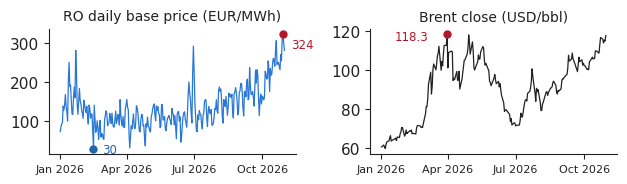

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.3))
axs[0].plot(ro_.index, ro_.values, color=PAL['RO'], lw=0.9)
for dt, col in [(ro_.idxmax(), '#b2182b'), (ro_.idxmin(), '#2166ac')]:
    axs[0].plot([dt], [ro_[dt]], 'o', color=col, ms=5)
    axs[0].annotate(f'{ro_[dt]:.0f}', (dt, ro_[dt]), textcoords='offset points', xytext=(6, -3 if col == '#2166ac' else -10),
                    fontsize=8.5, color=col)
axs[0].set_title('RO daily base price (EUR/MWh)', fontsize=10)
axs[1].plot(b_.index, b_.values, color='#222222', lw=0.9)
axs[1].plot([b_.idxmax()], [b_.max()], 'o', color='#b2182b', ms=5)
axs[1].annotate(f'{b_.max():.1f}', (b_.idxmax(), b_.max()), textcoords='offset points', xytext=(-38, -4), fontsize=8.5, color='#b2182b')
axs[1].set_title('Brent close (USD/bbl)', fontsize=10)
for ax in axs:
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.tick_params(axis='x', labelsize=8)
fig.tight_layout(rect=(0, 0.14, 1, 1))
plt.savefig('cy_extremes.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()